# 03 · QFT 与相位估计：把相位写进比特，再读出来

对应讲义实验 B · 前置：01 编程基础

**问题**：量子门 U 作用在它的本征态 $|\psi\rangle$ 上，只乘上一个相位：$U|\psi\rangle = e^{2\pi i\varphi}|\psi\rangle$。这个 φ 直接测量不到，却极有价值：Shor 算法分解大数、量子化学求分子能量，归根结底都是求某个门的 φ。相位估计（QPE）把 φ 读成 n 位二进制数。

**直觉**：受控 $U^{2^k}$ 把 φ 反冲到计数比特的相位上，形成的图案恰好是量子傅里叶变换（QFT）的输出；于是用逆 QFT，就能把相位变回比特。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import numpy as np
import matplotlib.pyplot as plt
from mindquantum import Circuit, UN, H, X, Power, PhaseShift, Measure, Simulator, qft
from mqlab import check, mystery_gate

## 1. QFT：把整数写进相位

`qft(range(n))` 生成 n 比特 QFT 线路：每个比特一个 H，加上 $n(n-1)/2$ 个受控相位门，末尾用 SWAP 交换比特顺序。

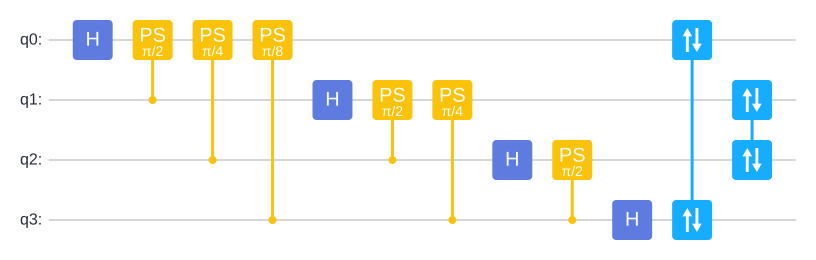

In [2]:
qft(range(4)).svg()

QFT 把基态 $|x\rangle$ 变成振幅大小全部相同、相位随 x 旋转的叠加态。对 $|101\rangle$（x = 5）做 QFT，再测量：

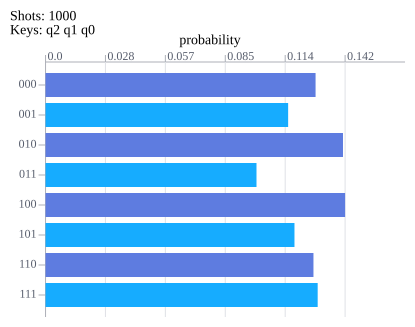

In [3]:
circ = Circuit([X.on(0), X.on(2)])     # |101⟩
circ += qft(range(3))
circ += UN(Measure(), 3)
res = Simulator('mqvector', 3).sampling(circ, shots=1000, seed=1)
res.svg()

8 种结果均匀出现：x 的信息全在相位里，直接测量看不见。

试一试：在 `circ += qft(range(3))` 后面加一行 `circ += qft(range(3)).hermitian()`（逆 QFT），结果变回 `101`——藏在相位里的信息被读了出来。相位估计做的正是这件事。

## 2. 验证：QFT 就是离散傅里叶变换

调试量子程序的好习惯：用经典方法验证。QFT 对振幅做的正是离散傅里叶变换（DFT）。教科书把 q0 当作最高位，而 MindSpore Quantum 使用小端序，比较时要在前后各做一次比特反转。

In [4]:
n = 4
rng = np.random.default_rng(7)
psi = rng.normal(size=2 ** n) + 1j * rng.normal(size=2 ** n)
psi /= np.linalg.norm(psi)                     # 随机量子态

sim = Simulator('mqvector', n)
sim.set_qs(psi)
sim.apply_circuit(qft(range(n)))               # 量子线路

rev = [int(f'{i:0{n}b}'[::-1], 2) for i in range(2 ** n)]   # 比特反转
ref = np.fft.ifft(psi[rev], norm='ortho')[rev]              # 经典 DFT
print(np.allclose(sim.get_qs(), ref))

True


QFT 只用 $O(n^2)$ 个门就完成了 $2^n$ 维的傅里叶变换，经典 FFT 需要 $O(n\,2^n)$ 次运算。但 QFT 的结果在振幅里，测量只能得到一个比特串：它不是“更快的 FFT”，而是把相位转换成比特的子程序。

## 3. 相位估计

神秘门 $U$ = `PhaseShift(2πφ)` 满足 $U|1\rangle = e^{2\pi i\varphi}|1\rangle$。线路分四步（计数比特 $q_0 \ldots q_{n-1}$，目标比特 $q_n$）：

1. 计数比特全部作用 H；目标比特用 X 制备到本征态 $|1\rangle$；
2. 受控 $U^{2^k}$：**最上面的计数比特控制最高次幂**，即 $q_i$ 控制 $U^{2^{n-1-i}}$。`Power(U, m).on(目标, 控制)` 表示受控的 $U^m$；
3. 对计数比特作用逆 QFT：`qft(range(n)).hermitian()`；
4. 测量计数比特。

下面是完整的程序（与讲义相同），采样 1,000 次：

φ ≈ 0.625


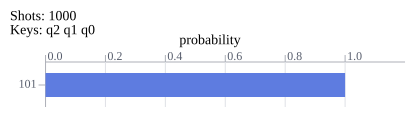

In [5]:
def qpe(U, n):
    circ = Circuit()
    circ += UN(H, n)
    circ += X.on(n)                                   # 目标比特 → 本征态 |1⟩
    for i in range(n):
        circ += Power(U, 2 ** i).on(n, n - 1 - i)     # q(n−1−i) 控制 U^(2^i)
    circ += qft(range(n)).hermitian()
    circ += UN(Measure(), n)
    return circ

true_phi = 0.625
U = PhaseShift(2 * np.pi * true_phi)          # 神秘门
n = 3
res = Simulator('mqvector', n + 1).sampling(qpe(U, n), shots=1000, seed=1)
bits = max(res.data, key=res.data.get)[::-1]  # 出现最多的比特串，反转
print('φ ≈', int(bits, 2) / 2 ** n)
res.svg()

1,000 次全部是 `101`，即 φ = 0.101₂ = 5/8 = 0.625。教科书的线路按大端序给出 φ 的二进制，MindSpore Quantum 却是小端序，所以读结果时要反转比特串；`101` 恰好是回文，看不出这一点。

### 现场改一改：先预测，再运行

直接修改上面的单元格，每次改一处，先写下预测再运行：

1. **换一个相位**：`true_phi = 0.375`。测到的比特串是？　A `011`　B `110`　C 两者各一半
2. **去掉逆 QFT**：删掉 `circ += qft(range(n)).hermitian()` 这一行。测量结果会怎样？　A 仍是 `101`　B 8 种结果均匀出现　C 全是 `000`
3. **相位无法用 3 位表示**：`true_phi = 1 / 3`。φ 的估计会怎样？　A 报错　B 总是 0.375　C 分散，峰值在 0.375

第 2 处改完，记得把这一行加回来。

<details><summary>答案</summary>

1. B：1,000 次都是 `110`，反转后为 `011`，即 φ = 3/8 = 0.375。只有非回文的比特串，才能检验比特序是否处理正确。
2. B：8 种结果各约 125 次，打印出的 φ 估计也就没有意义了。相位信息仍在计数比特里，只是计算基测量看不见它（对照第 1 节）；逆 QFT 的作用正是把相位变成比特。
3. C：结果分散，`110`（反转后 0.375）约占七成。计数比特越多，峰值越接近 1/3，见第 4 节。
</details>

## 4. 深入：精度由计数比特数决定

φ = 1/3 = 0.0101…₂ 不能写成有限位的二进制小数。此时结果不再确定，而是集中在最接近的 $k/2^n$ 附近；每多一个计数比特，精度翻一倍。

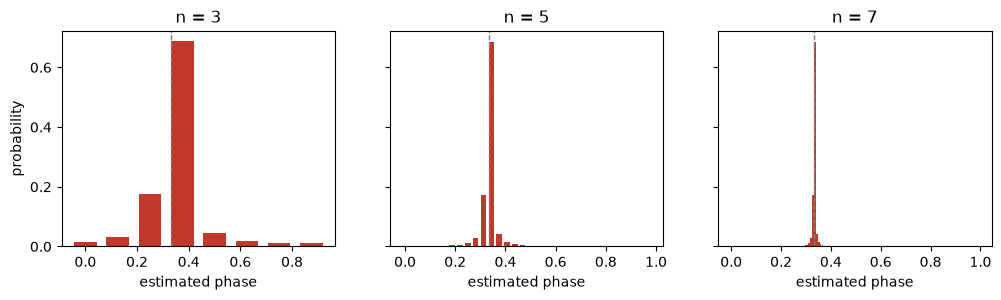

In [6]:
phi = 1 / 3
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, m in zip(axes, [3, 5, 7]):
    sim = Simulator('mqvector', m + 1)
    sim.apply_circuit(qpe(PhaseShift(2 * np.pi * phi), m).remove_measure())
    p = (np.abs(sim.get_qs()) ** 2).reshape(2, -1).sum(axis=0)   # 计数比特的分布
    est = [int(f'{i:0{m}b}'[::-1], 2) / 2 ** m for i in range(2 ** m)]
    ax.bar(est, p, width=0.7 / 2 ** m, color='#c0392b')
    ax.axvline(phi, color='0.5', ls='--', lw=1)
    ax.set_title(f'n = {m}')
    ax.set_xlabel('estimated phase')
axes[0].set_ylabel('probability')
plt.show()

## 课后挑战 · 破解神秘量子门

`mystery_gate()` 返回一个单比特门 U，满足 $U|1\rangle = e^{2\pi i\varphi}|1\rangle$，但 φ 未知。用第 3 节的 `qpe(U, n)` 找出 φ：先用 n = 3 试试，结果确定吗？要几个计数比特，才能把 φ 读准？

In [7]:
U = mystery_gate()
# 挑战：用 qpe(U, n) 估计 φ
### BEGIN SOLUTION
for n in range(3, 8):
    res = Simulator('mqvector', n + 1).sampling(qpe(U, n), shots=1000, seed=1)
    if len(res.data) == 1:                    # 结果确定：φ 恰好是 n 位二进制小数
        break
bits = max(res.data, key=res.data.get)[::-1]
phi = int(bits, 2) / 2 ** n
print(f'{n} 个计数比特：φ = {phi}')
### STUDENT: phi = ...
### END SOLUTION
check.mystery_phase(phi)

5 个计数比特：φ = 0.40625
✅ 通过：φ = 13/32 = 0.40625：要 5 个计数比特，采样结果才完全确定


## 小结

- QFT 用 $O(n^2)$ 个门完成 $2^n$ 维的傅里叶变换，但结果在振幅里，无法直接读出。
- 相位估计用受控 $U^{2^k}$ 把相位写进计数比特，再用逆 QFT 读出；n 个计数比特给出 n 位二进制精度。
- Shor 算法分解大数，本质上就是对“模乘”门做相位估计。